# UTCI Heatwave Sulawesi 1996–2025 — Combined Journal-Style Notebook

Notebook gabungan ini merangkum workflow UTCI yang sebelumnya tercecer di beberapa notebook menjadi **satu alur plot utama** bergaya jurnal internasional.

## Output utama
1. **Peta klimatologi mean daily UTCImax** 1996–2025.
2. **Perbandingan threshold kalender-harian P90 dan P95** + selisih P95−P90.
3. **Sensitivitas spasial** P90/P95 × minimum 3/4/5 hari (ditampilkan untuk HWF).
4. **Sensitivitas time series** untuk HWN, HWF, HWD, HWA, HWM.
5. **Peta karakteristik heatwave UTCI**: HWN, HWF, HWD, HWA, HWM.
6. **Time series karakteristik heatwave UTCI** dengan annual series, running mean 5 tahun, tren Theil–Sen, dan p-value Kendall.

## Definisi metodologis
- Definisi utama default: **P90-D3** (`MAIN_SCENARIO = "P90_D3"`).
- Sensitivitas: **P90/P95 × D3/D4/D5**.
- Threshold dihitung dengan **calendar-day percentile** memakai **15-day centered window**.
- Heatwave event: `UTCImax > threshold` selama sedikitnya `D` hari berturut-turut.
- **HWN** = jumlah event per tahun.
- **HWF** = total hari heatwave per tahun.
- **HWD** = durasi maksimum heatwave per tahun.
- **HWA** = nilai maksimum UTCImax pada hari heatwave (mode absolut) atau exceedance maksimum di atas threshold (mode excess).
- **HWM** = nilai rata-rata UTCImax pada hari heatwave (mode absolut) atau exceedance rata-rata di atas threshold (mode excess).

## Catatan input
Notebook ini **langsung memakai file daily maximum UTCI** hasil STEP 2 (`03_utci_dailymax_1996_2025_C_sulawesi.nc`). Jadi lebih ringan daripada mengulang QC file jam-jaman dari nol. Kalau file itu belum ada, jalankan dulu notebook STEP 1–2 milikmu.


## 0. Instalasi paket (jalankan hanya jika perlu)

```bash
pip install numpy pandas xarray netCDF4 matplotlib cartopy shapely scipy openpyxl
```


In [1]:
# ============================================================
# 1. IMPORT + KONFIGURASI UTAMA
# ============================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import theilslopes, kendalltau

import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------------------------------------------
# PATH — UBAH JIKA FOLDERMU BERBEDA
# ------------------------------------------------------------
RESULT_DIR = Path(r"D:\MERLI\data\UTCI_Hasil")
INPUT_FILE = RESULT_DIR / "03_utci_dailymax_1996_2025_C_sulawesi.nc"
OUTPUT_DIR = RESULT_DIR / "UTCI_Heatwave_Journal_Combined_Output"
PLOT_DIR = OUTPUT_DIR / "plots"
DATA_DIR = OUTPUT_DIR / "data"

for folder in [OUTPUT_DIR, PLOT_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PERIODE DAN DEFINISI HEATWAVE
# ------------------------------------------------------------
START_YEAR = 1996
END_YEAR = 2025
YEARS = np.arange(START_YEAR, END_YEAR + 1, dtype=int)

WINDOW_DAYS = 15
WINDOW_HALF = WINDOW_DAYS // 2
PERCENTILES = [90, 95]
MIN_DURATIONS = [3, 4, 5]
SCENARIOS = [f"P{p}_D{d}" for p in PERCENTILES for d in MIN_DURATIONS]
MAIN_SCENARIO = "P90_D3"

# HWA/HWM untuk figure utama
INTENSITY_MODE = "absolute"   # pilih: "absolute" atau "excess"

# PETA + OUTPUT
MAP_EXTENT = [118.0, 127.0, -7.0, 2.5]
FIG_DPI = 400
SAVE_PDF = True
ROBUST_COLOR_LIMITS = True

# STYLE JURNAL
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.titlesize": 14,
    "axes.linewidth": 0.8,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"File daily maximum UTCI tidak ditemukan:\n{INPUT_FILE}\n"
        "Jalankan dulu UTCI STEP 2 atau ubah path INPUT_FILE."
    )

if WINDOW_DAYS % 2 == 0:
    raise ValueError("WINDOW_DAYS harus ganjil.")

if MAIN_SCENARIO not in SCENARIOS:
    raise ValueError(f"MAIN_SCENARIO harus salah satu dari {SCENARIOS}")

if INTENSITY_MODE not in {"absolute", "excess"}:
    raise ValueError("INTENSITY_MODE harus 'absolute' atau 'excess'.")

print("INPUT FILE     :", INPUT_FILE)
print("OUTPUT DIR     :", OUTPUT_DIR)
print("Periode        :", START_YEAR, "–", END_YEAR)
print("Main scenario  :", MAIN_SCENARIO)
print("All scenarios  :", SCENARIOS)
print("Intensity mode :", INTENSITY_MODE)


INPUT FILE     : D:\MERLI\data\UTCI_Hasil\03_utci_dailymax_1996_2025_C_sulawesi.nc
OUTPUT DIR     : D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output
Periode        : 1996 – 2025
Main scenario  : P90_D3
All scenarios  : ['P90_D3', 'P90_D4', 'P90_D5', 'P95_D3', 'P95_D4', 'P95_D5']
Intensity mode : absolute


## 2. Buka daily maximum UTCI dan QC cepat

Cell ini membaca hasil STEP 2 dan memeriksa:
- nama variabel `utci_max`;
- kontinuitas tanggal 1996–2025;
- grid valid Sulawesi;
- rentang nilai UTCI.


In [2]:
# ============================================================
# 2. LOAD INPUT DAILY MAX UTCI
# ============================================================

ds = xr.open_dataset(
    INPUT_FILE,
    engine="netcdf4",
    decode_times=True,
    decode_timedelta=False,
)

if "utci_max" not in ds.data_vars:
    raise ValueError("Variabel 'utci_max' tidak ditemukan di INPUT_FILE.")

utci = ds["utci_max"].transpose("time", "latitude", "longitude")
values = np.asarray(utci.values, dtype=np.float32)
lat = np.asarray(ds["latitude"].values, dtype=float)
lon = np.asarray(ds["longitude"].values, dtype=float)
dates = pd.DatetimeIndex(utci["time"].values)

expected_dates = pd.date_range(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31", freq="D")
if len(dates) != len(expected_dates):
    raise ValueError("Jumlah hari input tidak sesuai 1996–2025.")
if len(dates[dates.duplicated()]) != 0:
    raise ValueError("Ada tanggal duplikat dalam data UTCI harian.")
if len(expected_dates.difference(dates)) != 0:
    raise ValueError("Ada tanggal yang hilang dalam data UTCI harian.")

valid = np.isfinite(values)
valid_grid = np.any(valid, axis=0)

print("Shape values :", values.shape)
print("Latitude     :", lat.min(), "s.d.", lat.max(), "| n =", len(lat))
print("Longitude    :", lon.min(), "s.d.", lon.max(), "| n =", len(lon))
print("Periode      :", dates.min(), "s.d.", dates.max())
print("Grid valid   :", int(valid_grid.sum()))
print("UTCI min     :", float(np.nanmin(values)), "°C")
print("UTCI max     :", float(np.nanmax(values)), "°C")


Shape values : (10958, 44, 32)
Latitude     : -6.25 s.d. 4.5 | n = 44
Longitude    : 119.0 s.d. 126.75 | n = 32
Periode      : 1996-01-01 00:00:00 s.d. 2025-12-31 00:00:00
Grid valid   : 242
UTCI min     : 18.56707763671875 °C
UTCI max     : 44.473175048828125 °C


## 3. Helper plotting jurnal

Semua peta memakai:
- extent yang sama;
- coastline;
- batas provinsi Sulawesi/Gorontalo;
- gridline label minimal;
- shared helper untuk robust color limits.


In [3]:
# ============================================================
# 3. HELPER PLOTTING
# ============================================================

def get_sulawesi_geometries():
    admin1 = shpreader.natural_earth(
        resolution="10m",
        category="cultural",
        name="admin_1_states_provinces",
    )
    reader = shpreader.Reader(admin1)
    geoms = []
    for record in reader.records():
        text = " ".join(
            str(v).lower()
            for v in record.attributes.values()
            if v is not None
        )
        if "indonesia" not in text:
            continue
        if ("sulawesi" in text) or ("gorontalo" in text):
            geoms.append(record.geometry)
    return geoms

SUL_GEOMS = get_sulawesi_geometries()


def masked(field):
    arr = np.asarray(field, dtype=float).copy()
    arr[~valid_grid] = np.nan
    return arr


def robust_limits(arrays, low=2, high=98, symmetric=False):
    if not isinstance(arrays, (list, tuple)):
        arrays = [arrays]
    vals = []
    for a in arrays:
        a = np.asarray(a)
        f = a[np.isfinite(a)]
        if f.size:
            vals.append(f)
    if not vals:
        return (-1.0, 1.0) if symmetric else (0.0, 1.0)
    vals = np.concatenate(vals)
    if symmetric:
        vmax = float(np.nanpercentile(np.abs(vals), high))
        if (not np.isfinite(vmax)) or (vmax == 0):
            vmax = float(np.nanmax(np.abs(vals))) if vals.size else 1.0
        return -vmax, vmax
    if ROBUST_COLOR_LIMITS:
        vmin = float(np.nanpercentile(vals, low))
        vmax = float(np.nanpercentile(vals, high))
    else:
        vmin = float(np.nanmin(vals))
        vmax = float(np.nanmax(vals))
    if np.isclose(vmin, vmax):
        vmin = float(np.nanmin(vals))
        vmax = float(np.nanmax(vals))
        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6
    return vmin, vmax


def setup_map_ax(ax, left_labels=True, bottom_labels=True):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m", linewidth=0.6)
    for geom in SUL_GEOMS:
        ax.add_geometries(
            [geom],
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="0.25",
            linewidth=0.45,
            zorder=5,
        )
    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.25,
        linestyle=":",
        alpha=0.45,
        x_inline=False,
        y_inline=False,
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left_labels
    gl.bottom_labels = bottom_labels
    gl.xlabel_style = {"size": 7}
    gl.ylabel_style = {"size": 7}


def save_figure(fig, stem):
    png = PLOT_DIR / f"{stem}.png"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    if SAVE_PDF:
        pdf = PLOT_DIR / f"{stem}.pdf"
        fig.savefig(pdf, bbox_inches="tight", facecolor="white")
    print("Tersimpan:", png)
    return png


## 4. Figure 1 — Peta spatial mean daily UTCImax

Ini bukan HWA/HWM. Ini adalah **klimatologi rata-rata semua nilai daily maximum UTCI** periode 1996–2025.


Tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots\FIG01_Mean_Daily_UTCImax_Sulawesi_1996_2025.png


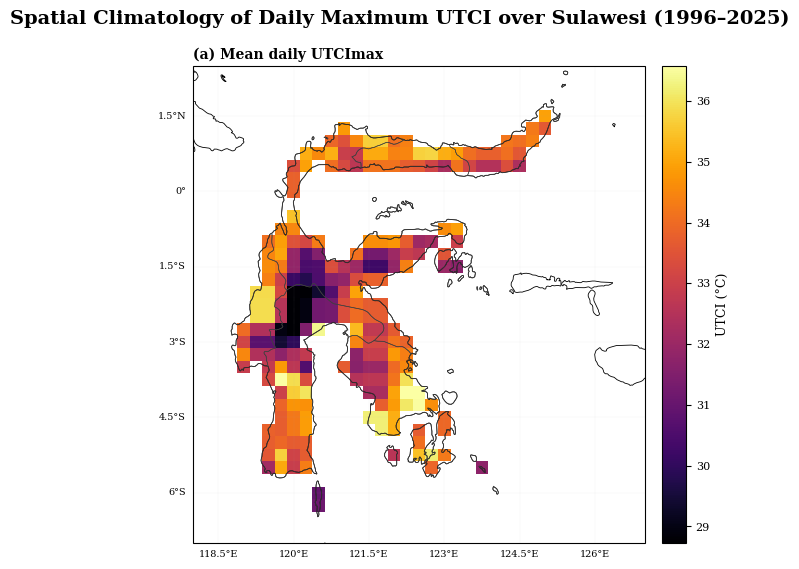

In [4]:
# ============================================================
# FIGURE 1 — MEAN DAILY UTCIMAX CLIMATOLOGY
# ============================================================

mean_daily_utci = masked(np.nanmean(values, axis=0))
vmin, vmax = robust_limits(mean_daily_utci, low=1, high=99)

fig = plt.figure(figsize=(7.2, 6.2))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
mesh = ax.pcolormesh(
    lon,
    lat,
    mean_daily_utci,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
    shading="nearest",
    transform=ccrs.PlateCarree(),
    rasterized=True,
)
setup_map_ax(ax, left_labels=True, bottom_labels=True)
ax.set_title("(a) Mean daily UTCImax", fontweight="bold", loc="left", pad=5)
cb = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.046, pad=0.03)
cb.set_label("UTCI (°C)")

fig.suptitle(
    f"Spatial Climatology of Daily Maximum UTCI over Sulawesi ({START_YEAR}–{END_YEAR})",
    fontweight="bold",
    y=0.97,
)

save_figure(fig, "FIG01_Mean_Daily_UTCImax_Sulawesi_1996_2025")
plt.show()
plt.close(fig)


## 5. Threshold kalender-harian P90 dan P95

- Kalender referensi memakai **365 hari**.
- 29 Februari tidak dipakai saat membentuk klimatologi.
- Threshold 29 Februari saat diproyeksikan kembali ke deret waktu harian diambil dari rata-rata threshold 28 Februari dan 1 Maret.


In [5]:
# ============================================================
# 5. CALENDAR-DAY P90 / P95 THRESHOLD (15-DAY WINDOW)
# ============================================================

# Template non-leap year untuk indeks 0..364
cal_template = pd.date_range("2001-01-01", "2001-12-31", freq="D")
month_day_template = [(d.month, d.day) for d in cal_template]
month_day_to_index = {md: i for i, md in enumerate(month_day_template)}

clim_index = np.full(len(dates), -1, dtype=np.int16)
for t, date in enumerate(dates):
    md = (date.month, date.day)
    if md == (2, 29):
        clim_index[t] = -1
    else:
        clim_index[t] = month_day_to_index[md]

nlat, nlon = values.shape[1], values.shape[2]
threshold_calendar = np.full((len(PERCENTILES), 365, nlat, nlon), np.nan, dtype=np.float32)
sample_counts = []

valid_clim = clim_index >= 0

for d in range(365):
    window_days = [(d + off) % 365 for off in range(-WINDOW_HALF, WINDOW_HALF + 1)]
    time_mask = valid_clim & np.isin(clim_index, window_days)
    sample = values[time_mask, :, :]
    sample_counts.append(sample.shape[0])
    p_result = np.nanpercentile(sample, PERCENTILES, axis=0).astype(np.float32)
    threshold_calendar[:, d, :, :] = p_result

thresholds = {
    f"P{p}": threshold_calendar[i]
    for i, p in enumerate(PERCENTILES)
}

threshold_ds = xr.Dataset(
    {
        "P90": (("dayofyear", "latitude", "longitude"), threshold_calendar[0]),
        "P95": (("dayofyear", "latitude", "longitude"), threshold_calendar[1]),
    },
    coords={
        "dayofyear": np.arange(1, 366, dtype=np.int16),
        "latitude": lat,
        "longitude": lon,
    },
)

threshold_file = DATA_DIR / "UTCI_Thresholds_P90_P95_Calendar15day_1996_2025.nc"
threshold_ds.to_netcdf(threshold_file)
print("Threshold file:", threshold_file)
print("Sample count min/max:", min(sample_counts), "/", max(sample_counts))


Threshold file: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\data\UTCI_Thresholds_P90_P95_Calendar15day_1996_2025.nc
Sample count min/max: 450 / 450


## 6. Figure 2 — Perbandingan P90 dan P95

Panel (a) dan (b) memakai skala warna yang sama, sedangkan panel (c) menampilkan **P95 − P90**.


Tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots\FIG02_P90_P95_Threshold_Comparison_UTCI.png


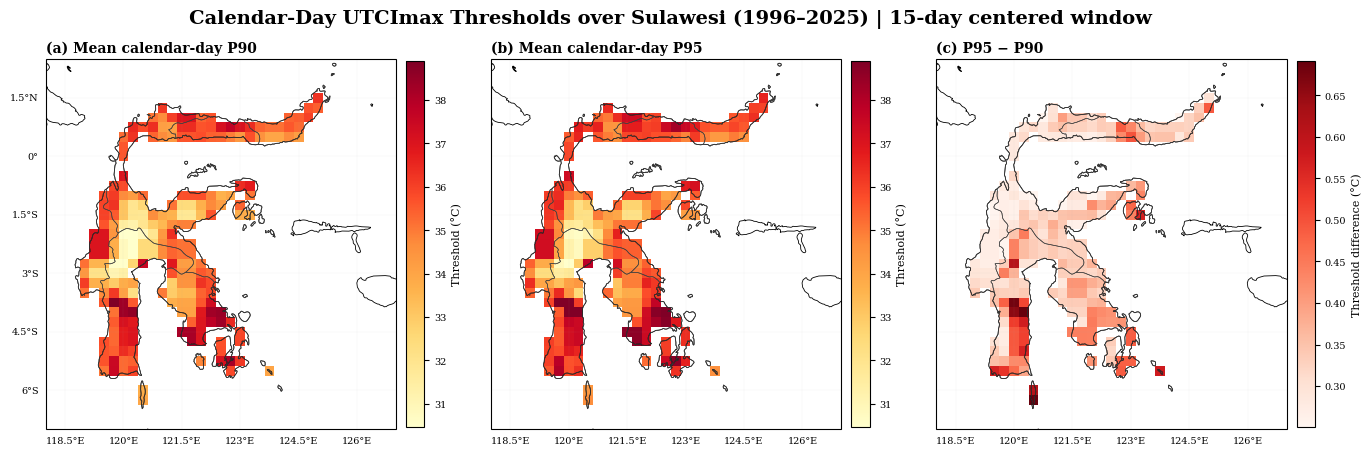

In [6]:
# ============================================================
# FIGURE 2 — P90 vs P95 THRESHOLD COMPARISON
# ============================================================

p90_mean = masked(np.nanmean(thresholds["P90"], axis=0))
p95_mean = masked(np.nanmean(thresholds["P95"], axis=0))
delta_95_90 = masked(p95_mean - p90_mean)

thr_vmin, thr_vmax = robust_limits([p90_mean, p95_mean], low=1, high=99)
d_vmin, d_vmax = robust_limits(delta_95_90, low=1, high=99)

fig = plt.figure(figsize=(14.0, 5.0))
gs = fig.add_gridspec(1, 3, wspace=0.12, left=0.04, right=0.96, bottom=0.12, top=0.86)

panels = [
    (p90_mean, "(a) Mean calendar-day P90", "YlOrRd", thr_vmin, thr_vmax, "Threshold (°C)"),
    (p95_mean, "(b) Mean calendar-day P95", "YlOrRd", thr_vmin, thr_vmax, "Threshold (°C)"),
    (delta_95_90, "(c) P95 − P90", "Reds", d_vmin, d_vmax, "Threshold difference (°C)"),
]

for i, (z, title, cmap, vmin, vmax, label) in enumerate(panels):
    ax = fig.add_subplot(gs[0, i], projection=ccrs.PlateCarree())
    mesh = ax.pcolormesh(
        lon, lat, z,
        cmap=cmap, vmin=vmin, vmax=vmax,
        shading="nearest", transform=ccrs.PlateCarree(), rasterized=True,
    )
    setup_map_ax(ax, left_labels=(i == 0), bottom_labels=True)
    ax.set_title(title, fontweight="bold", loc="left", pad=5)
    cb = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.046, pad=0.025)
    cb.set_label(label, fontsize=8)
    cb.ax.tick_params(labelsize=7)

fig.suptitle(
    f"Calendar-Day UTCImax Thresholds over Sulawesi ({START_YEAR}–{END_YEAR}) | {WINDOW_DAYS}-day centered window",
    fontweight="bold", y=0.96,
)

save_figure(fig, "FIG02_P90_P95_Threshold_Comparison_UTCI")
plt.show()
plt.close(fig)


## 7. Deteksi event heatwave dan lima karakteristik

Notebook menghitung semua enam skenario:
- `P90_D3`, `P90_D4`, `P90_D5`
- `P95_D3`, `P95_D4`, `P95_D5`

Semua hasil tahunan disimpan dalam dimensi:

`percentile × min_duration × year × latitude × longitude`


In [7]:
# ============================================================
# 7. EVENT DETECTION + ANNUAL METRICS
# ============================================================

idx_feb28 = month_day_to_index[(2, 28)]
idx_mar01 = month_day_to_index[(3, 1)]

def build_daily_threshold(calendar_threshold):
    """
    calendar_threshold: shape (365, lat, lon)
    return daily threshold over full 1996–2025 time axis
    """
    daily = np.full(values.shape, np.nan, dtype=np.float32)
    feb29_threshold = (calendar_threshold[idx_feb28] + calendar_threshold[idx_mar01]) / 2.0
    for t, date in enumerate(dates):
        if (date.month == 2) and (date.day == 29):
            daily[t] = feb29_threshold
        else:
            daily[t] = calendar_threshold[clim_index[t]]
    daily[~valid] = np.nan
    return daily


def heatwave_runs_1d(exceed_1d, min_duration):
    b = np.asarray(exceed_1d, dtype=bool)
    padded = np.concatenate(([False], b, [False]))
    changes = np.diff(padded.astype(np.int8))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]
    durations = ends - starts
    keep = durations >= min_duration
    valid_starts = starts[keep]
    valid_ends = ends[keep]
    valid_durations = durations[keep]
    event_mask = np.zeros(b.shape, dtype=bool)
    for start, end in zip(valid_starts, valid_ends):
        event_mask[start:end] = True
    return event_mask, valid_durations


years = np.arange(START_YEAR, END_YEAR + 1, dtype=np.int16)
date_years = dates.year.values
shape_out = (len(PERCENTILES), len(MIN_DURATIONS), len(years), nlat, nlon)

def new_metric_array():
    return np.full(shape_out, np.nan, dtype=np.float32)

HWN = new_metric_array()
HWF = new_metric_array()
HWD = new_metric_array()
HWA_excess = new_metric_array()
HWM_excess = new_metric_array()
HWA_abs = new_metric_array()
HWM_abs = new_metric_array()

grid_indices = np.argwhere(valid_grid)

for pi, percentile in enumerate(PERCENTILES):
    print("\n==============================")
    print(f"MEMPROSES P{percentile}")
    print("==============================")
    daily_threshold = build_daily_threshold(threshold_calendar[pi])
    exceed = valid & (values > daily_threshold)

    for di, min_duration in enumerate(MIN_DURATIONS):
        print(f"--- P{percentile} | ≥{min_duration} hari ---")
        for yi, year in enumerate(years):
            tidx = np.where(date_years == year)[0]
            ex_y = exceed[tidx]
            val_y = values[tidx]
            thr_y = daily_threshold[tidx]

            for ii, jj in grid_indices:
                event_mask, durations = heatwave_runs_1d(ex_y[:, ii, jj], min_duration)

                HWN[pi, di, yi, ii, jj] = float(len(durations))
                HWD[pi, di, yi, ii, jj] = float(durations.max()) if len(durations) > 0 else 0.0
                HWF[pi, di, yi, ii, jj] = float(event_mask.sum())

                if event_mask.any():
                    hw_abs = val_y[event_mask, ii, jj]
                    hw_excess = val_y[event_mask, ii, jj] - thr_y[event_mask, ii, jj]
                    HWA_abs[pi, di, yi, ii, jj] = float(np.nanmax(hw_abs))
                    HWM_abs[pi, di, yi, ii, jj] = float(np.nanmean(hw_abs))
                    HWA_excess[pi, di, yi, ii, jj] = float(np.nanmax(hw_excess))
                    HWM_excess[pi, di, yi, ii, jj] = float(np.nanmean(hw_excess))
                else:
                    HWA_abs[pi, di, yi, ii, jj] = np.nan
                    HWM_abs[pi, di, yi, ii, jj] = np.nan
                    HWA_excess[pi, di, yi, ii, jj] = np.nan
                    HWM_excess[pi, di, yi, ii, jj] = np.nan

# Simpan ke Dataset xarray
metrics_ds = xr.Dataset(
    {
        "HWN": (("percentile", "min_duration", "year", "latitude", "longitude"), HWN),
        "HWF": (("percentile", "min_duration", "year", "latitude", "longitude"), HWF),
        "HWD": (("percentile", "min_duration", "year", "latitude", "longitude"), HWD),
        "HWA_abs": (("percentile", "min_duration", "year", "latitude", "longitude"), HWA_abs),
        "HWM_abs": (("percentile", "min_duration", "year", "latitude", "longitude"), HWM_abs),
        "HWA_excess": (("percentile", "min_duration", "year", "latitude", "longitude"), HWA_excess),
        "HWM_excess": (("percentile", "min_duration", "year", "latitude", "longitude"), HWM_excess),
    },
    coords={
        "percentile": np.asarray(PERCENTILES, dtype=np.int16),
        "min_duration": np.asarray(MIN_DURATIONS, dtype=np.int8),
        "year": years,
        "latitude": lat,
        "longitude": lon,
    }
)

metrics_file = DATA_DIR / "UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc"
metrics_ds.to_netcdf(metrics_file)
print("Metrics file:", metrics_file)



MEMPROSES P90
--- P90 | ≥3 hari ---
--- P90 | ≥4 hari ---
--- P90 | ≥5 hari ---

MEMPROSES P95
--- P95 | ≥3 hari ---
--- P95 | ≥4 hari ---
--- P95 | ≥5 hari ---
Metrics file: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\data\UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc


## 8. Area-weighted annual mean untuk Sulawesi

Rata-rata regional dihitung memakai bobot `cos(latitude)` supaya sedikit lebih rapi dibanding mean grid mentah.


In [8]:
# ============================================================
# 8. AREA-WEIGHTED REGIONAL MEAN + TABEL ANNUAL
# ============================================================

lat_weights = np.cos(np.deg2rad(lat)).astype(float)
weights_2d = np.repeat(lat_weights[:, None], len(lon), axis=1)
weights_2d[~valid_grid] = np.nan


def area_weighted_mean(field2d):
    z = np.asarray(field2d, dtype=float)
    mask = np.isfinite(z) & np.isfinite(weights_2d)
    if not np.any(mask):
        return np.nan
    return float(np.nansum(z[mask] * weights_2d[mask]) / np.nansum(weights_2d[mask]))


scenario_results = {}
annual_rows = []

for pi, percentile in enumerate(PERCENTILES):
    for di, duration in enumerate(MIN_DURATIONS):
        scenario = f"P{percentile}_D{duration}"
        result = {
            "HWN": HWN[pi, di],
            "HWF": HWF[pi, di],
            "HWD": HWD[pi, di],
            "HWA_abs": HWA_abs[pi, di],
            "HWM_abs": HWM_abs[pi, di],
            "HWA_excess": HWA_excess[pi, di],
            "HWM_excess": HWM_excess[pi, di],
        }
        scenario_results[scenario] = result

        for yi, year in enumerate(years):
            annual_rows.append({
                "scenario": scenario,
                "percentile": percentile,
                "min_duration_days": duration,
                "year": int(year),
                "HWN": area_weighted_mean(result["HWN"][yi]),
                "HWF": area_weighted_mean(result["HWF"][yi]),
                "HWD": area_weighted_mean(result["HWD"][yi]),
                "HWA_abs": area_weighted_mean(result["HWA_abs"][yi]),
                "HWM_abs": area_weighted_mean(result["HWM_abs"][yi]),
                "HWA_excess": area_weighted_mean(result["HWA_excess"][yi]),
                "HWM_excess": area_weighted_mean(result["HWM_excess"][yi]),
            })

annual_df = pd.DataFrame(annual_rows)
annual_df.head()


,scenario,percentile,min_duration_days,year,HWN,HWF,HWD,HWA_abs,HWM_abs,HWA_excess,HWM_excess
0,P90_D3,90,3,1996,1.247853,4.450191,2.843167,35.494081,34.736058,1.151047,0.567637
1,P90_D3,90,3,1997,1.107187,4.850291,2.594713,35.974520,35.144006,1.174364,0.574607
2,P90_D3,90,3,1998,5.555097,22.437768,5.498895,36.402439,35.028998,1.611807,0.600758
3,P90_D3,90,3,1999,0.500045,1.665427,1.103207,35.659564,35.197061,0.942959,0.533183
4,P90_D3,90,3,2000,0.929914,3.186544,2.182058,35.710879,35.074528,0.980892,0.512046


## 9. Figure 3 — Sensitivitas spasial P90/P95 × D3/D4/D5

Untuk peta sensitivity, ditampilkan **HWF (days/year)** karena paling mudah dibaca secara spasial.


Tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots\FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5.png


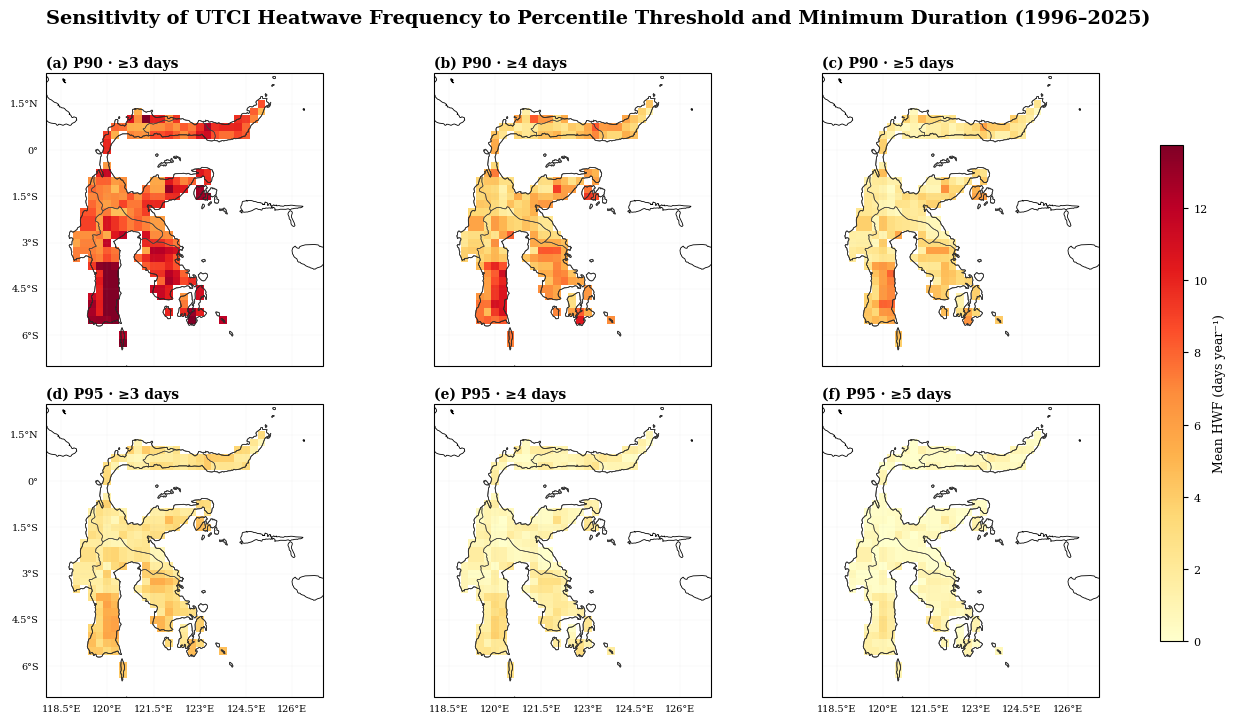

In [9]:
# ============================================================
# FIGURE 3 — SENSITIVITY SPATIAL HWF
# ============================================================

hwf_maps = {scenario: masked(np.nanmean(scenario_results[scenario]["HWF"], axis=0)) for scenario in SCENARIOS}
svmin, svmax = robust_limits(list(hwf_maps.values()), low=1, high=99)

fig = plt.figure(figsize=(13.2, 8.0))
gs = fig.add_gridspec(2, 3, wspace=0.08, hspace=0.13, left=0.05, right=0.91, bottom=0.10, top=0.88)

mesh = None
for i, scenario in enumerate(SCENARIOS):
    row, col = i // 3, i % 3
    ax = fig.add_subplot(gs[row, col], projection=ccrs.PlateCarree())
    mesh = ax.pcolormesh(
        lon, lat, hwf_maps[scenario],
        cmap="YlOrRd", vmin=svmin, vmax=svmax,
        shading="nearest", transform=ccrs.PlateCarree(), rasterized=True,
    )
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    setup_map_ax(ax, left_labels=(col == 0), bottom_labels=(row == 1))
    ax.set_title(f"({chr(97+i)}) P{p} · ≥{d} days", fontweight="bold", loc="left", pad=4)

cax = fig.add_axes([0.925, 0.17, 0.018, 0.62])
cb = fig.colorbar(mesh, cax=cax, orientation="vertical")
cb.set_label("Mean HWF (days year⁻¹)")

fig.suptitle(
    f"Sensitivity of UTCI Heatwave Frequency to Percentile Threshold and Minimum Duration ({START_YEAR}–{END_YEAR})",
    fontweight="bold", y=0.96,
)

save_figure(fig, "FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5")
plt.show()
plt.close(fig)


## 10. Figure 4 — Sensitivitas time series lima karakteristik

Warna membedakan **minimum duration**, sedangkan garis solid/dashed membedakan **P90 vs P95**.


Tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots\FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics.png


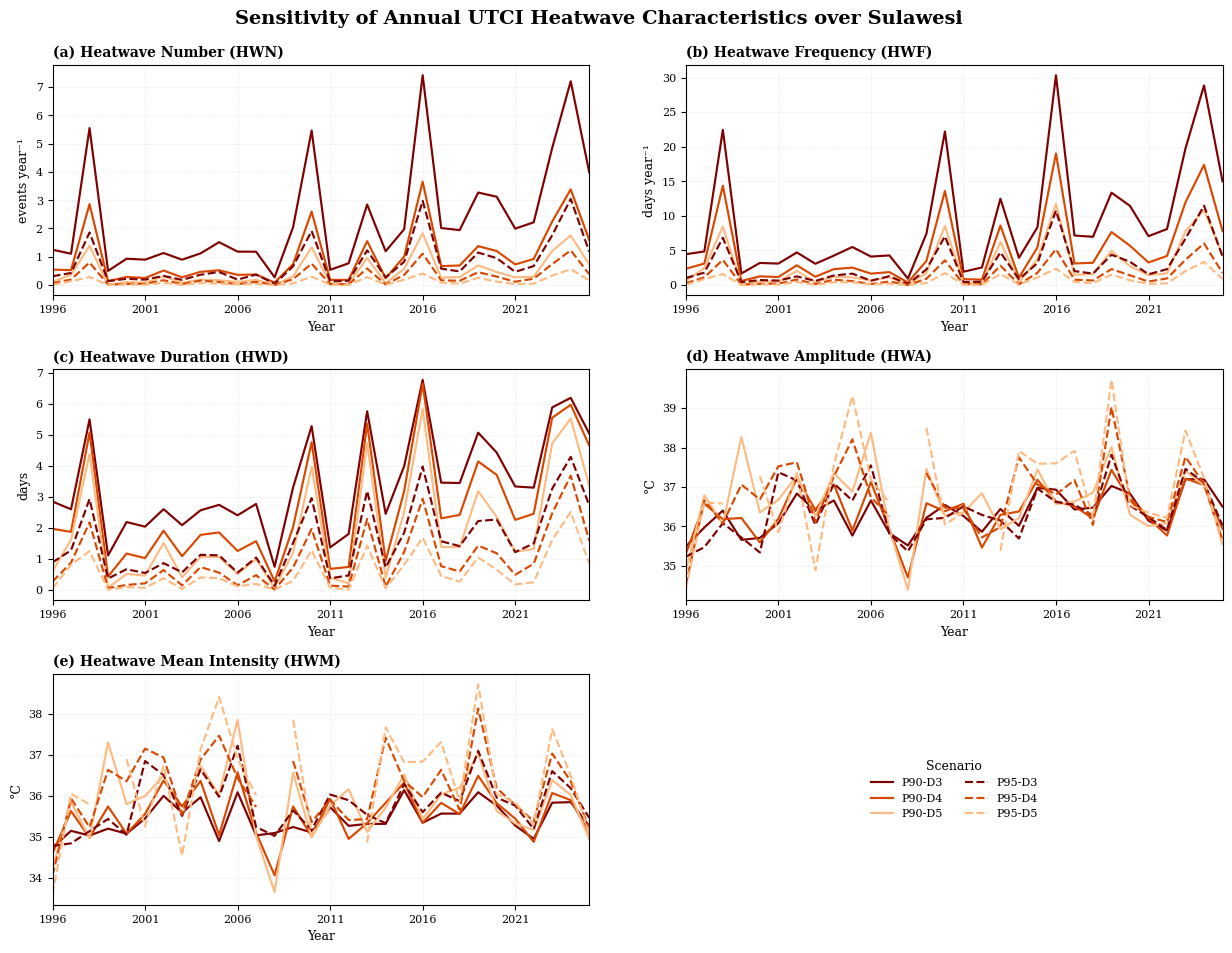

In [10]:
# ============================================================
# FIGURE 4 — SENSITIVITY TIME SERIES
# ============================================================

if INTENSITY_MODE == "absolute":
    hwa_metric, hwm_metric = "HWA_abs", "HWM_abs"
    intensity_unit = "°C"
else:
    hwa_metric, hwm_metric = "HWA_excess", "HWM_excess"
    intensity_unit = "°C above threshold"

plot_metrics = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹"),
    ("HWD", "Heatwave Duration (HWD)", "days"),
    (hwa_metric, "Heatwave Amplitude (HWA)", intensity_unit),
    (hwm_metric, "Heatwave Mean Intensity (HWM)", intensity_unit),
]

duration_colors = {3: "#7f0000", 4: "#d94801", 5: "#fdbb84"}
percentile_styles = {90: "-", 95: "--"}

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

axes = []
for i, (metric, title, ylabel) in enumerate(plot_metrics):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    axes.append(ax)
    for scenario in SCENARIOS:
        p = int(re.search(r"P(\d+)", scenario).group(1))
        d = int(re.search(r"D(\d+)", scenario).group(1))
        sub = annual_df[annual_df["scenario"] == scenario].sort_values("year")
        ax.plot(
            sub["year"], sub[metric],
            color=duration_colors[d], linestyle=percentile_styles[p],
            linewidth=1.55, label=f"P{p}-D{d}",
        )
    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Year")
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
ax_leg.legend(handles, labels, loc="center", frameon=False, ncol=2, title="Scenario")

fig.suptitle(
    "Sensitivity of Annual UTCI Heatwave Characteristics over Sulawesi",
    fontweight="bold", y=0.965,
)

save_figure(fig, "FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics")
plt.show()
plt.close(fig)


## 11. Figure 5 — Peta karakteristik heatwave UTCI

Figure utama mengikuti `MAIN_SCENARIO`.


Tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots\FIG05_Spatial_UTCI_Heatwave_Characteristics_P90_D3_absolute.png


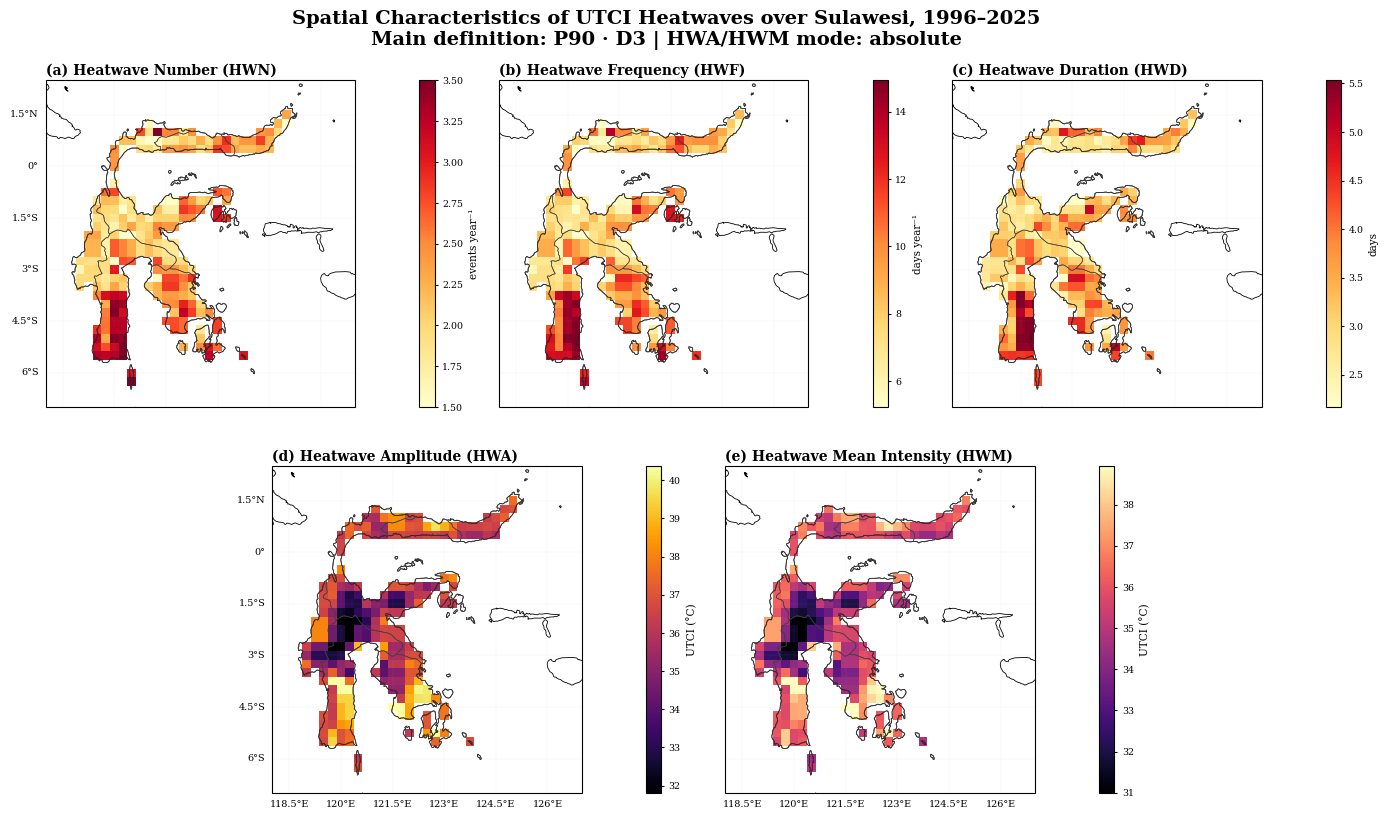

In [11]:
# ============================================================
# FIGURE 5 — SPATIAL CHARACTERISTICS UTCI HEATWAVES
# ============================================================

main = scenario_results[MAIN_SCENARIO]

if INTENSITY_MODE == "absolute":
    hwa_key, hwm_key = "HWA_abs", "HWM_abs"
    hwa_label, hwm_label = "UTCI (°C)", "UTCI (°C)"
else:
    hwa_key, hwm_key = "HWA_excess", "HWM_excess"
    hwa_label, hwm_label = "°C above threshold", "°C above threshold"

map_specs = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹", "YlOrRd"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹", "YlOrRd"),
    ("HWD", "Heatwave Duration (HWD)", "days", "YlOrRd"),
    (hwa_key, "Heatwave Amplitude (HWA)", hwa_label, "inferno"),
    (hwm_key, "Heatwave Mean Intensity (HWM)", hwm_label, "magma"),
]

positions = [(0, 0, 2), (0, 2, 2), (0, 4, 2), (1, 1, 2), (1, 3, 2)]
fig = plt.figure(figsize=(14.5, 8.8))
outer = fig.add_gridspec(2, 6, hspace=0.18, wspace=0.05, left=0.035, right=0.965, bottom=0.07, top=0.88)

for i, ((metric, title, unit, cmap), pos) in enumerate(zip(map_specs, positions)):
    row, col, colspan = pos
    inner = outer[row, col:col+colspan].subgridspec(1, 2, width_ratios=[0.965, 0.035], wspace=0.05)
    ax = fig.add_subplot(inner[0, 0], projection=ccrs.PlateCarree())
    z = masked(np.nanmean(main[metric], axis=0))
    vmin, vmax = robust_limits(z, low=2, high=98)
    mesh = ax.pcolormesh(
        lon, lat, z,
        cmap=cmap, vmin=vmin, vmax=vmax,
        shading="nearest", transform=ccrs.PlateCarree(), rasterized=True,
    )
    setup_map_ax(ax, left_labels=(col <= 1), bottom_labels=(row == 1))
    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left", pad=4)
    cax = fig.add_subplot(inner[0, 1])
    cb = fig.colorbar(mesh, cax=cax, orientation="vertical")
    cb.set_label(unit, fontsize=7.5)
    cb.ax.tick_params(labelsize=6.8, length=2)

fig.suptitle(
    f"Spatial Characteristics of UTCI Heatwaves over Sulawesi, {START_YEAR}–{END_YEAR}\n"
    f"Main definition: {MAIN_SCENARIO.replace('_', ' · ')} | HWA/HWM mode: {INTENSITY_MODE}",
    fontweight="bold", y=0.96,
)

save_figure(fig, f"FIG05_Spatial_UTCI_Heatwave_Characteristics_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)


## 12. Figure 6 — Time series utama + Theil–Sen trend

Format mengikuti plot jurnal yang kamu suka:
- garis abu tipis = nilai tahunan;
- garis merah = running mean 5 tahun;
- garis hitam putus = Theil–Sen trend;
- kotak anotasi = slope per decade + p-value Kendall.


Tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots\FIG06_Main_TimeSeries_UTCI_TheilSen_P90_D3_absolute.png


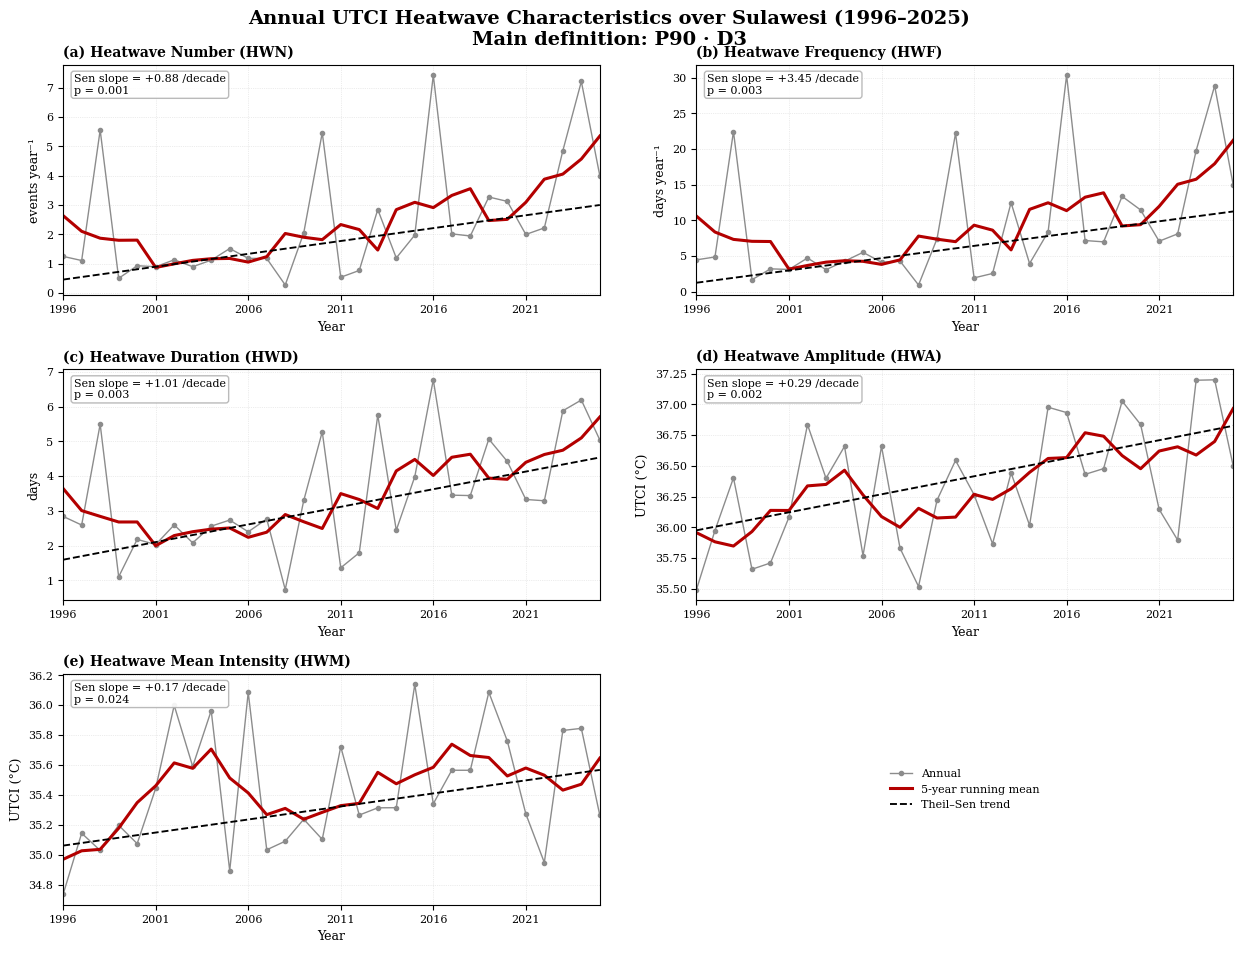

,metric,slope_per_decade,kendall_p
0,HWN,0.876729,0.000654
1,HWF,3.446248,0.003269
2,HWD,1.014867,0.002543
3,HWA_abs,0.292965,0.001966
4,HWM_abs,0.174490,0.023648


In [12]:
# ============================================================
# FIGURE 6 — MAIN TIME SERIES + THEIL-SEN + KENDALL
# ============================================================

main_df = annual_df[annual_df["scenario"] == MAIN_SCENARIO].sort_values("year").copy()

main_metrics = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹"),
    ("HWD", "Heatwave Duration (HWD)", "days"),
    (hwa_key, "Heatwave Amplitude (HWA)", hwa_label),
    (hwm_key, "Heatwave Mean Intensity (HWM)", hwm_label),
]

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

trend_rows = []
legend_handles = None
legend_labels = None

for i, (metric, title, ylabel) in enumerate(main_metrics):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    x = main_df["year"].to_numpy(dtype=float)
    y = main_df[metric].to_numpy(dtype=float)
    valid_xy = np.isfinite(x) & np.isfinite(y)

    line1, = ax.plot(x, y, color="0.55", linewidth=1.0, marker="o", markersize=3.0, label="Annual")
    rolling = pd.Series(y).rolling(5, center=True, min_periods=3).mean().to_numpy()
    line2, = ax.plot(x, rolling, color="#b30000", linewidth=2.2, label="5-year running mean")

    if valid_xy.sum() >= 10:
        ts = theilslopes(y[valid_xy], x[valid_xy], alpha=0.95)
        trend = ts.intercept + ts.slope * x
        mk = kendalltau(x[valid_xy], y[valid_xy], nan_policy="omit")
        line3, = ax.plot(x, trend, color="black", linestyle="--", linewidth=1.35, label="Theil–Sen trend")
        slope_dec = ts.slope * 10.0
        pval = mk.pvalue
        ax.text(
            0.02, 0.96,
            f"Sen slope = {slope_dec:+.2f} /decade\np = {pval:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", alpha=0.9),
        )
        trend_rows.append({"metric": metric, "slope_per_decade": slope_dec, "kendall_p": pval})
    else:
        line3 = None

    if legend_handles is None:
        legend_handles = [h for h in [line1, line2, line3] if h is not None]
        legend_labels = [h.get_label() for h in legend_handles]

    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
ax_leg.legend(legend_handles, legend_labels, loc="center", frameon=False)

fig.suptitle(
    f"Annual UTCI Heatwave Characteristics over Sulawesi ({START_YEAR}–{END_YEAR})\n"
    f"Main definition: {MAIN_SCENARIO.replace('_', ' · ')}",
    fontweight="bold", y=0.965,
)

save_figure(fig, f"FIG06_Main_TimeSeries_UTCI_TheilSen_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)

trend_summary_df = pd.DataFrame(trend_rows)
trend_summary_df


Main scenario : P90_D3
Intensity mode: absolute

Province geometry check:
Sulawesi Selatan    : 1 geometry
Sulawesi Tengah     : 1 geometry
Sulawesi Tenggara   : 1 geometry
Sulawesi Barat      : 1 geometry
Sulawesi Utara      : 1 geometry
Gorontalo           : 1 geometry

Province grid check:
Sulawesi Selatan    :  65 grid
Sulawesi Tengah     :  77 grid
Sulawesi Tenggara   :  43 grid
Sulawesi Barat      :  21 grid
Sulawesi Utara      :  19 grid
Gorontalo           :  17 grid

Regional UTCI dataframe:


,year,region,metric,value
0,1996,Sulawesi Selatan,HWN,1.292131
1,1996,Sulawesi Selatan,HWF,4.584110
2,1996,Sulawesi Selatan,HWD,2.815553
3,1996,Sulawesi Selatan,HWA_abs,35.219295
4,1996,Sulawesi Selatan,HWM_abs,34.484710
5,1996,Sulawesi Tengah,HWN,1.428508
6,1996,Sulawesi Tengah,HWF,5.220549
7,1996,Sulawesi Tengah,HWD,3.259650
8,1996,Sulawesi Tengah,HWA_abs,35.216500
9,1996,Sulawesi Tengah,HWM_abs,34.394935


,region,metric,count,mean,min,max
0,Gorontalo,HWA_abs,30,37.091280,35.636326,38.311200
1,Gorontalo,HWD,30,2.939213,0.470564,6.176480
2,Gorontalo,HWF,30,8.168640,0.470564,33.941365
3,Gorontalo,HWM_abs,30,36.326569,34.917653,37.782374
4,Gorontalo,HWN,30,2.209807,0.117641,8.941221
5,Sulawesi Barat,HWA_abs,30,36.000389,33.288696,37.208301
6,Sulawesi Barat,HWD,30,2.953997,0.142795,6.476321
7,Sulawesi Barat,HWF,30,7.549309,0.142795,31.905233
8,Sulawesi Barat,HWM_abs,30,35.423449,32.766998,36.785819
9,Sulawesi Barat,HWN,30,2.023828,0.047598,7.904634


Tersimpan: D:\MERLI\data\TMAX_Hasil\Plot_Heatwave_PaperStyle\FIG07_Province_TimeSeries_UTCI_P90_D3_absolute.png


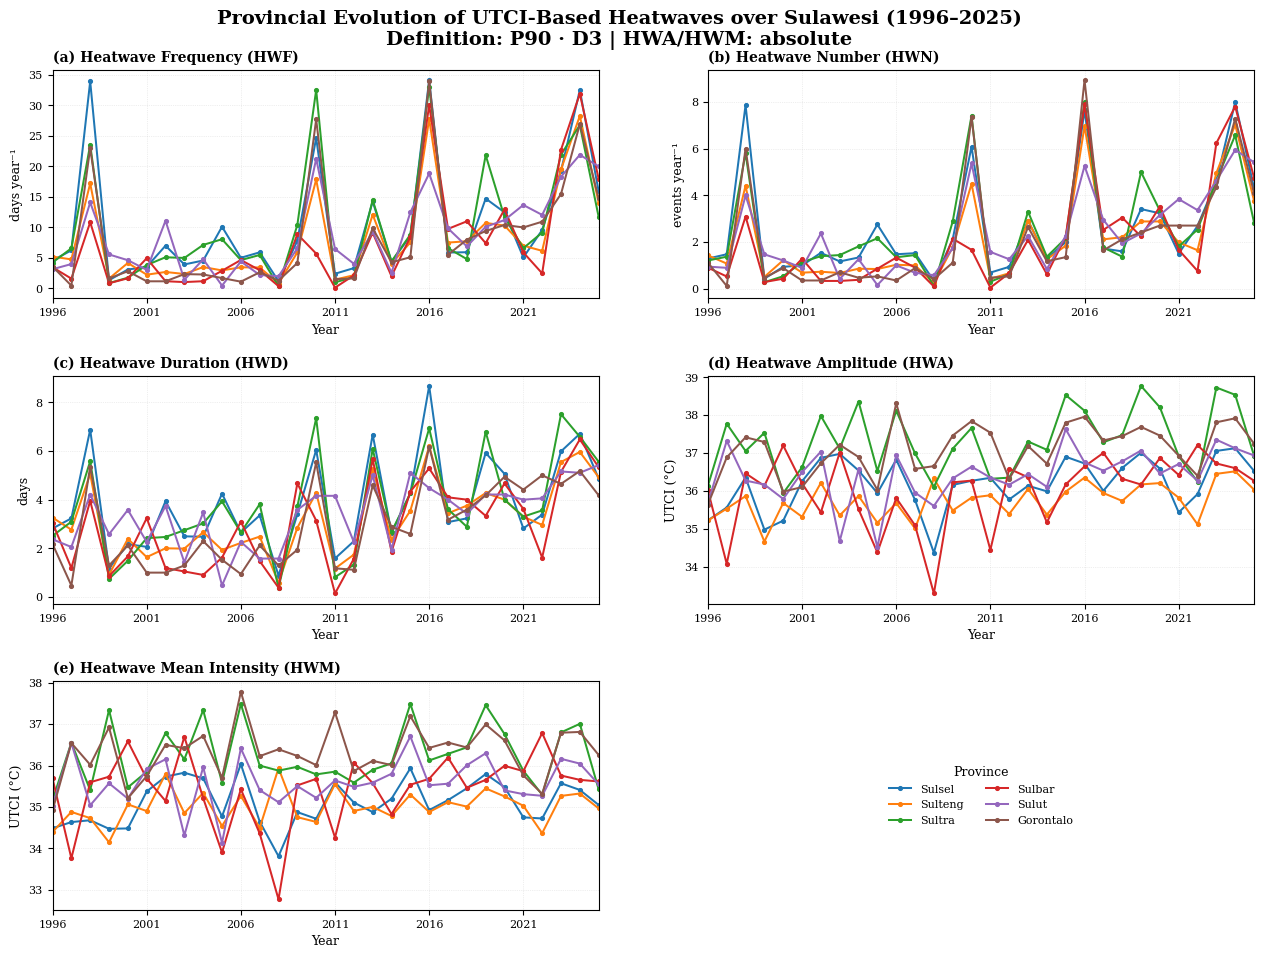

CSV tersimpan: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\data\UTCI_Province_TimeSeries_P90_D3_absolute.csv


In [16]:
# ============================================================
# FIGURE 7 — PROVINCE TIME SERIES UTCI (MAIN SCENARIO)
# HWN, HWF, HWD, HWA, HWM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.io.shapereader as shpreader

# ------------------------------------------------------------
# 1. PASTIKAN YEAR AXIS TERSEDIA
# ------------------------------------------------------------

if "years" in globals():
    YEAR_AXIS = np.asarray(years, dtype=int)
elif "YEARS" in globals():
    YEAR_AXIS = np.asarray(YEARS, dtype=int)
else:
    YEAR_AXIS = np.arange(START_YEAR, END_YEAR + 1)

# ------------------------------------------------------------
# 2. GRID 2-D
# ------------------------------------------------------------

lon2d, lat2d = np.meshgrid(lon, lat)

# ------------------------------------------------------------
# 3. DEFINISI HWA / HWM
# ------------------------------------------------------------

if INTENSITY_MODE == "absolute":
    hwa_key = "HWA_abs"
    hwm_key = "HWM_abs"

    hwa_label = "UTCI (°C)"
    hwm_label = "UTCI (°C)"

else:
    hwa_key = "HWA_excess"
    hwm_key = "HWM_excess"

    hwa_label = "°C above threshold"
    hwm_label = "°C above threshold"

# ------------------------------------------------------------
# 4. DATA SKENARIO UTAMA
# ------------------------------------------------------------

main = scenario_results[MAIN_SCENARIO]

print("Main scenario :", MAIN_SCENARIO)
print("Intensity mode:", INTENSITY_MODE)


# ============================================================
# 5. BUAT MASK 6 PROVINSI SULAWESI
# ============================================================

province_order = [
    "Sulawesi Selatan",
    "Sulawesi Tengah",
    "Sulawesi Tenggara",
    "Sulawesi Barat",
    "Sulawesi Utara",
    "Gorontalo",
]

province_short = {
    "Sulawesi Selatan": "Sulsel",
    "Sulawesi Tengah": "Sulteng",
    "Sulawesi Tenggara": "Sultra",
    "Sulawesi Barat": "Sulbar",
    "Sulawesi Utara": "Sulut",
    "Gorontalo": "Gorontalo",
}

# Nama yang mungkin muncul pada Natural Earth
province_aliases = {
    "Sulawesi Selatan": [
        "sulawesi selatan",
        "south sulawesi",
    ],
    "Sulawesi Tengah": [
        "sulawesi tengah",
        "central sulawesi",
    ],
    "Sulawesi Tenggara": [
        "sulawesi tenggara",
        "southeast sulawesi",
        "south east sulawesi",
    ],
    "Sulawesi Barat": [
        "sulawesi barat",
        "west sulawesi",
    ],
    "Sulawesi Utara": [
        "sulawesi utara",
        "north sulawesi",
    ],
    "Gorontalo": [
        "gorontalo",
    ],
}


# ------------------------------------------------------------
# SHAPELY contains_xy
# ------------------------------------------------------------

try:
    from shapely import contains_xy

    def geom_contains(geom, x, y):
        return contains_xy(geom, x, y)

except ImportError:

    from shapely import vectorized

    def geom_contains(geom, x, y):
        return vectorized.contains(
            geom,
            x,
            y
        )


# ------------------------------------------------------------
# BACA ADMIN-1 NATURAL EARTH
# ------------------------------------------------------------

admin1_file = shpreader.natural_earth(
    resolution="10m",
    category="cultural",
    name="admin_1_states_provinces",
)

reader = shpreader.Reader(
    admin1_file
)


# ------------------------------------------------------------
# CARI GEOMETRI SETIAP PROVINSI
# ------------------------------------------------------------

province_geometries = {
    province: []
    for province in province_order
}


for record in reader.records():

    attrs_text = " ".join(
        str(v).lower()
        for v in record.attributes.values()
        if v is not None
    )

    # hanya Indonesia
    if "indonesia" not in attrs_text:
        continue

    for province in province_order:

        aliases = province_aliases[
            province
        ]

        if any(
            alias in attrs_text
            for alias in aliases
        ):
            province_geometries[
                province
            ].append(
                record.geometry
            )


# ------------------------------------------------------------
# QC GEOMETRI
# ------------------------------------------------------------

print("\nProvince geometry check:")

for province in province_order:

    n_geom = len(
        province_geometries[
            province
        ]
    )

    print(
        f"{province:20s}: "
        f"{n_geom} geometry"
    )

    if n_geom == 0:
        raise RuntimeError(
            f"Geometri {province} tidak ditemukan."
        )


# ------------------------------------------------------------
# BUAT MASK GRID
# ------------------------------------------------------------

province_masks = {}


for province in province_order:

    mask = np.zeros(
        lat2d.shape,
        dtype=bool
    )

    for geom in province_geometries[
        province
    ]:

        mask |= geom_contains(
            geom,
            lon2d,
            lat2d
        )

    # hanya grid UTCI yang memang valid
    if "valid_grid" in globals():

        mask &= valid_grid

    province_masks[
        province
    ] = mask


print("\nProvince grid check:")

for province in province_order:

    print(
        f"{province:20s}: "
        f"{province_masks[province].sum():3d} grid"
    )


# ============================================================
# 6. AREA-WEIGHTED MEAN
# ============================================================

def regional_weighted_mean(
    field,
    region_mask
):

    """
    Area-weighted mean menggunakan cos(latitude).
    """

    field = np.asarray(
        field,
        dtype=float
    )

    region_mask = np.asarray(
        region_mask,
        dtype=bool
    )

    weights = np.where(
        region_mask,
        np.cos(
            np.deg2rad(
                lat2d
            )
        ),
        np.nan
    )

    valid_mask = (
        np.isfinite(field)
        &
        np.isfinite(weights)
    )

    if not np.any(
        valid_mask
    ):
        return np.nan

    return float(
        np.nansum(
            field[valid_mask]
            *
            weights[valid_mask]
        )
        /
        np.nansum(
            weights[valid_mask]
        )
    )


# ============================================================
# 7. BANGUN DATAFRAME PROVINSI
# ============================================================

metrics_to_extract = [
    "HWN",
    "HWF",
    "HWD",
    hwa_key,
    hwm_key,
]


regional_rows = []


for yi, year in enumerate(
    YEAR_AXIS
):

    for province in province_order:

        region_mask = province_masks[
            province
        ]

        for metric in metrics_to_extract:

            value = regional_weighted_mean(
                main[metric][yi],
                region_mask
            )

            regional_rows.append(
                {
                    "year": int(year),
                    "region": province,
                    "metric": metric,
                    "value": value,
                }
            )


regional_utci_df = pd.DataFrame(
    regional_rows
)


print("\nRegional UTCI dataframe:")
display(
    regional_utci_df.head(15)
)


# ============================================================
# 8. QC MISSING VALUE
# ============================================================

qc_province = (
    regional_utci_df
    .groupby(
        ["region", "metric"]
    )["value"]
    .agg(
        [
            "count",
            "mean",
            "min",
            "max"
        ]
    )
    .reset_index()
)

display(
    qc_province
)


# ============================================================
# 9. FIGURE — PROVINCE TIME SERIES
# ============================================================

province_metrics = [
    (
        "HWF",
        "Heatwave Frequency (HWF)",
        "days year⁻¹"
    ),
    (
        "HWN",
        "Heatwave Number (HWN)",
        "events year⁻¹"
    ),
    (
        "HWD",
        "Heatwave Duration (HWD)",
        "days"
    ),
    (
        hwa_key,
        "Heatwave Amplitude (HWA)",
        hwa_label
    ),
    (
        hwm_key,
        "Heatwave Mean Intensity (HWM)",
        hwm_label
    ),
]


fig = plt.figure(
    figsize=(13.5, 10.0)
)

gs = fig.add_gridspec(
    3,
    2,
    hspace=0.34,
    wspace=0.20,
    left=0.08,
    right=0.97,
    bottom=0.07,
    top=0.91,
)


axes = []


for i, (
    metric,
    title,
    ylabel
) in enumerate(
    province_metrics
):

    ax = fig.add_subplot(
        gs[
            i // 2,
            i % 2
        ]
    )

    axes.append(
        ax
    )


    for province in province_order:

        sub = regional_utci_df[
            (
                regional_utci_df[
                    "region"
                ]
                == province
            )
            &
            (
                regional_utci_df[
                    "metric"
                ]
                == metric
            )
        ].sort_values(
            "year"
        )


        ax.plot(
            sub["year"],
            sub["value"],
            linewidth=1.45,
            marker="o",
            markersize=2.7,
            label=province_short[
                province
            ],
        )


    ax.set_title(
        f"({chr(97+i)}) {title}",
        fontweight="bold",
        loc="left",
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_xlim(
        START_YEAR,
        END_YEAR
    )

    ax.set_xticks(
        np.arange(
            START_YEAR,
            END_YEAR + 1,
            5
        )
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.5,
        alpha=0.4,
    )


# ============================================================
# 10. PANEL LEGEND
# ============================================================

ax_leg = fig.add_subplot(
    gs[2, 1]
)

ax_leg.axis(
    "off"
)


handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)


ax_leg.legend(
    handles,
    labels,
    loc="center",
    frameon=False,
    ncol=2,
    fontsize=8,
    title="Province",
)


# X label hanya panel bawah
axes[4].set_xlabel(
    "Year"
)

# panel lain yang ada di row terakhir kalau diperlukan
for ax in axes[:4]:
    ax.set_xlabel(
        "Year"
    )


# ============================================================
# 11. TITLE
# ============================================================

fig.suptitle(
    f"Provincial Evolution of UTCI-Based Heatwaves over Sulawesi "
    f"({START_YEAR}–{END_YEAR})\n"
    f"Definition: {MAIN_SCENARIO.replace('_', ' · ')} | "
    f"HWA/HWM: {INTENSITY_MODE}",
    fontweight="bold",
    y=0.97,
)


# ============================================================
# 12. SAVE
# ============================================================

save_figure(
    fig,
    f"FIG07_Province_TimeSeries_UTCI_"
    f"{MAIN_SCENARIO}_"
    f"{INTENSITY_MODE}"
)

plt.show()
plt.close(
    fig
)


# ============================================================
# 13. EXPORT CSV
# ============================================================

province_csv = (
    DATA_DIR
    / (
        f"UTCI_Province_TimeSeries_"
        f"{MAIN_SCENARIO}_"
        f"{INTENSITY_MODE}.csv"
    )
)

regional_utci_df.to_csv(
    province_csv,
    index=False
)

print(
    "CSV tersimpan:",
    province_csv
)

## 13. Ringkasan sensitivity + ekspor Excel

Output tabel yang disimpan:
- annual metrics semua skenario;
- summary sensitivitas 30 tahun;
- summary threshold;
- trend summary untuk definisi utama.


In [13]:
# ============================================================
# 13. SUMMARY TABLE + EXPORT
# ============================================================

summary_rows = []
for scenario in SCENARIOS:
    sub = annual_df[annual_df["scenario"] == scenario]
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    summary_rows.append({
        "scenario": scenario,
        "percentile": p,
        "min_duration_days": d,
        "HWN_mean": sub["HWN"].mean(),
        "HWF_mean_days_per_year": sub["HWF"].mean(),
        "HWD_mean_days": sub["HWD"].mean(),
        "HWA_abs_mean_C": sub["HWA_abs"].mean(),
        "HWM_abs_mean_C": sub["HWM_abs"].mean(),
        "HWA_excess_mean_C": sub["HWA_excess"].mean(),
        "HWM_excess_mean_C": sub["HWM_excess"].mean(),
    })

sensitivity_summary_df = pd.DataFrame(summary_rows)
threshold_summary_df = pd.DataFrame([
    {
        "threshold": key,
        "mean_C": float(np.nanmean(arr)),
        "min_C": float(np.nanmin(arr)),
        "max_C": float(np.nanmax(arr)),
    }
    for key, arr in thresholds.items()
])

annual_csv = DATA_DIR / "Annual_UTCI_Heatwave_Metrics_All_Scenarios.csv"
annual_df.to_csv(annual_csv, index=False)

excel_path = DATA_DIR / "UTCI_Heatwave_Journal_Combined_1996_2025.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    annual_df.to_excel(writer, sheet_name="Annual_Metrics", index=False)
    sensitivity_summary_df.to_excel(writer, sheet_name="Sensitivity_Summary", index=False)
    threshold_summary_df.to_excel(writer, sheet_name="Threshold_Summary", index=False)
    trend_summary_df.to_excel(writer, sheet_name="Trend_Main", index=False)

print("CSV  :", annual_csv)
print("Excel:", excel_path)
print("\nPlot folder:", PLOT_DIR)
print("\nDaftar PNG:")
for p in sorted(PLOT_DIR.glob("*.png")):
    print(" -", p.name)


CSV  : D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\data\Annual_UTCI_Heatwave_Metrics_All_Scenarios.csv
Excel: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\data\UTCI_Heatwave_Journal_Combined_1996_2025.xlsx

Plot folder: D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output\plots

Daftar PNG:
 - FIG01_Mean_Daily_UTCImax_Sulawesi_1996_2025.png
 - FIG02_P90_P95_Threshold_Comparison_UTCI.png
 - FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5.png
 - FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics.png
 - FIG05_Spatial_UTCI_Heatwave_Characteristics_P90_D3_absolute.png
 - FIG06_Main_TimeSeries_UTCI_TheilSen_P90_D3_absolute.png


## 14. Daftar output akhir

Target output utama yang akan muncul di folder `plots`:
- `FIG01_Mean_Daily_UTCImax_Sulawesi_1996_2025`
- `FIG02_P90_P95_Threshold_Comparison_UTCI`
- `FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5`
- `FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics`
- `FIG05_Spatial_UTCI_Heatwave_Characteristics_<MAIN_SCENARIO>_<INTENSITY_MODE>`
- `FIG06_Main_TimeSeries_UTCI_TheilSen_<MAIN_SCENARIO>_<INTENSITY_MODE>`

Kalau kamu mau versi utama **P95-D3**, ganti saja:

```python
MAIN_SCENARIO = "P95_D3"
```

Kalau kamu mau HWA/HWM sebagai **excess above threshold**, ganti:

```python
INTENSITY_MODE = "excess"
```
